In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q matplotlib pytest numpy
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    os.chdir(repo_root)
    print("💻 ローカル開発環境を検出しました。作業ディレクトリ:", os.getcwd())


💻 ローカル開発環境を検出しました。作業ディレクトリ: /home/student/Documents/GitHub/study-mikanos


# 8.7 メモリ管理に挑戦 (`osbook_day08c`)

本節では、名著『ゼロからのOS自作入門』第8章「メモリ管理」の集大成として、OS カーネルが物理 RAM を 4KiB の**ページフレーム（Page Frame）**単位で動的に割り当て・解放するための中核コンポーネント **`BitmapMemoryManager`（ビットマップ方式物理メモリマネージャ）**を設計・実装し、UEFI `MemoryMap` との統合およびホスト環境での単体テストまでを徹底的に探究します。

---

## 🎯 本節の学習到達目標

1. **物理メモリマネージャ（PMM）の役割と 8.6 節ページングとの責務分離**:
   - `ExitBootServices()` 後の世界で、なぜ恒等ページング（64GiB アクセス可能化）だけでは動的なメモリ貸し出しができないのかを理解する。
   - 4KiB ページフレーム管理層（第8章 `BitmapMemoryManager`）とバイト単位ヒープ管理層（第9章 `sbrk` / `malloc` / `new`）の階層構造を把握する。
2. **ビットマップ方式の数理と圧倒的な空間効率の導出**:
   - 1 ビットで 4KiB（$32,768$ ビット）を追跡する空間オーバーヘッド $\frac{1}{32,768} \approx 0.00305\%$ を導出し、128GiB の広大な物理空間をわずか **4MiB** の配列で管理できることを証明する。
   - ユーザー定義リテラル（`_KiB`, `_MiB`, `_GiB`）と強い型付け `FrameID` / 番兵 `kNullFrame` の設計意図を理解する。
3. **4MiB オブジェクトの配置と `.bss` 配置 `new`（Placement `new`）の必然性**:
   - `sizeof(BitmapMemoryManager) = 4,194,320` バイト（約 4MiB）を 8.4 節のカーネルスタック（`1MiB`）にローカル変数として置くと即座にスタックオーバーフローする理由と、フリースタンディング環境での Placement `new` 解法を理解する。
4. **2次元ビット座標変換と C++ 64ビット左シフトの罠**:
   - `alloc_map_`（`uint64_t` 配列）における行インデックス $n = \lfloor f / 64 \rfloor$ とビット位置 $m = f \bmod 64$ の変換式、および `1 << bit_index`（32ビット符号付き `int`）が引き起こす符号拡張破壊・未定義動作（UB）を解明する。
5. **First-Fit 連続領域探索の $\mathcal{O}(N)$ ジャンプ最適化と外部断片化**:
   - `Allocate(num_frames)` における `start_frame_id += i + 1` スキップ更新が探索計算量を $\mathcal{O}(N \cdot k)$ から $\mathcal{O}(N)$ へ削減する数学的根拠と、`Free()` による隣接空きビット自動合体（Auto-Coalescing）・外部断片化（External Fragmentation）の挙動を定量検証する。
6. **UEFI `MemoryMap` 走査初期化の 3 大不変条件とホスト単体テスト (`CppUTest`)**:
   - `KernelMainNewStack` における未記載メモリホール（VGA/ROM 領域等）の保護、`EfiLoaderData` によるカーネル自身の保護、および `FrameID{1}` 開始による `nullptr`（`0x0000`）衝突回避の仕組みを理解し、C++20 & Python で完全再現する。


---

## 1. なぜ OS に「物理ページフレーム管理」が必要なのか？

### 1.1 UEFI からの完全独立と 8.6 節ページングとの役割分担

第8章の前半〜中盤にかけて、MikanOS カーネルは UEFI ファームウェアへの依存を段階的に断ち切ってきました。

- **第4章 (`ExitBootServices`)**: ブートローダが UEFI ブートサービスを終了した瞬間から、UEFI のメモリ確保 API（`gBS->AllocatePages` / `AllocatePool`）は永久に呼び出し不能となりました。同時に、ブートローダは物理メモリの地図である **`MemoryMap`** をカーネルへ引き渡しました（8.2 節）。
- **8.3 節〜8.6 節**: UEFI 管理下にあったデータ構造・スタック（1MiB `kernel_main_stack`）・GDT（セグメンテーション）・4階層ページテーブル（64GiB 恒等マッピング）をすべてカーネル自身の `.bss` セクションへ移設しました。

しかし、ここで極めて重要な疑問が生じます。
**「8.6 節で 64GiB の恒等ページングを設定したのだから、もう好きなメモリアドレスを読み書きできるのでは？」**

答えは **「アクセスできること（Addressability）」と「安全に貸し出せること（Allocation）」は全く別問題である** という点にあります。

```
+-----------------------------------------------------------------------------------+
| 【第9章以降】C++ 標準ライブラリ / カーネル動的オブジェクト層                      |
|   new Layer / std::vector / malloc(size)  --> バイト単位 (数B 〜 数MiB) の要求    |
+-----------------------------------------------------------------------------------+
                                        │  メモリ不足時に sbrk() で追加ページを要求
                                        ▼
+-----------------------------------------------------------------------------------+
| 【8.7 節: 本節の主役！】物理ページフレーム管理層 (BitmapMemoryManager)            |
|   Allocate(num_frames) / Free(frame, num_frames)                                  |
|   ・4 KiB (1 ページフレーム) 単位で「空き(0) / 使用中(1)」を一元台帳管理！        |
|   ・BIOS ROM ホールやカーネル自身 (.text/.data/.bss) の上書き事故を絶対阻止！     |
+-----------------------------------------------------------------------------------+
                                        │  UEFI MemoryMap から初期台帳を構築
                                        ▼
+-----------------------------------------------------------------------------------+
| 【8.6 節】MMU 仮想記憶・恒等ページング層 (SetupIdentityPageTable)                 |
|   仮想アドレス V == 物理アドレス P (0 〜 64 GiB) のハードウェア変換のみを提供     |
+-----------------------------------------------------------------------------------+
```

もし台帳（メモリマネージャ）なしに適当なアドレス（例：`0x00200000`）へ新しいウィンドウバッファやキューを配置すれば、別のサブシステムが同じ番地を使ってデータを破壊したり、PC アーキテクチャ特有の **メモリホール（VGA VRAM や BIOS ROM がマップされた物理空間の穴）** や **カーネル自身の機械語コード領域** を踏み抜いて即座にクラッシュしてしまいます。

この階層関係を Mermaid フローチャートで整理すると次のようになります。

```mermaid
flowchart TD
    UEFI["UEFI MemoryMap (8.2節)<br/>物理RAM・ROM穴・Kernel領域の記述子群"] --> INIT["KernelMainNewStack 初期化ループ (8.7節)<br/>穴と非空き領域を MarkAllocated(1)"]
    INIT --> BMM["BitmapMemoryManager (8.7節)<br/>128GiB = 33,554,432 フレーム (4MiB ビットマップ)"]
    BMM -->|"Allocate(k) -> FrameID"| SBRK["program_break / sbrk (第9章)<br/>Newlib malloc / C++ operator new"]
    BMM -->|"Allocate(k) -> FrameID"| PT["動的ページテーブル・アプリ空間 (第19〜20章)<br/>4KiB ページフレームの動的割当"]
    SBRK -->|"Free() / 再利用"| BMM
```

---

### 1.2 管理単位「4KiB ページフレーム」とビットマップ方式の数理

OS が物理メモリを管理する際、1 バイト単位で空き状況の台帳を作ると台帳自体が物理メモリと同等の巨大サイズになってしまいます。そこで現代のほぼすべての汎用 OS（Linux, Windows, macOS, MikanOS）は、物理 RAM を一定のブロックサイズで区切った **ページフレーム（Page Frame：単にフレームとも呼ぶ）** 単位で管理します。

MikanOS が **1 フレーム = 4 KiB（$4,096$ バイト = $2^{12}$ バイト）** を採用する理由は 3 つあります：
1. **x86-64 MMU ハードウェアとの完全一致**: 8.6 節で学んだ通り、x86-64 ページングの最小ページサイズ（Level 1 PT の 1 エントリ）が厳密に **4 KiB** であり、将来アプリごとに仮想アドレス空間を分離する際にそのままページテーブルへ登録できるため。
2. **UEFI `MemoryMap` との完全一致**: UEFI 仕様における `MemoryDescriptor::number_of_pages` の 1 ページ単位も厳密に **4 KiB** であるため。
3. **驚異的な空間オーバーヘッド削減**:
   ビットマップ方式（1 フレームにつき `0`=空き / `1`=使用中 の **1 ビット** を割り当てる方式）を採用した場合、1 フレーム（$4,096 \text{ Bytes} = 4,096 \times 8 = 32,768 \text{ bits}$）あたりの管理用メモリ比率は次式で与えられます：

$$\text{Space Overhead} = \frac{1 \text{ bit}}{4,096 \times 8 \text{ bits}} = \frac{1}{32,768} \approx 0.000030517578\dots \;(\mathbf{0.00305\%})$$

代表的な物理メモリ管理アルゴリズムを比較すると、OS ブート直後の基盤アロケータとしてビットマップ方式がいかに優れているかが一目瞭然です。

| 比較項目 | ビットマップ方式 (`BitmapMemoryManager`) | フリーリスト方式（単方向連結リスト） | バディシステム（Buddy System: Linux 等） |
| :--- | :--- | :--- | :--- |
| **データ構造** | 固定長ビット配列（1 bit / Frame） | 空きフレーム先頭に次ポインタを埋め込む | $2^k$ オーダー別の空きブロック連結リスト配列 |
| **空間オーバーヘッド** | **極めて小さい（固定 $0.00305\%$）** | 空き領域内を使うため外部配列は 0 B | `struct page` 配列等で約 $1.5\%$ 前後 |
| **$k$ 連続フレーム確保** | **任意の $k$ 個を線形探索 $\mathcal{O}(N)$ で確保可能** | アドレス順ソート維持が必要で複雑 | $2^m$ 個単位に丸められ内部断片化が発生 |
| **解放 (`Free`) 計算量** | **$\mathcal{O}(k)$（1 フレームなら厳密に $\mathcal{O}(1)$）** | ソート挿入・隣接結合で $\mathcal{O}(N)$ | バディ合体判定で $\mathcal{O}(\log N)$ |
| **動的ヒープへの依存** | **ゼロ（静的 `.bss` 配列のみで完結！）** | ゼロ（ただし空きページへの直接書込が必須） | メタデータ配列の初期化が必要 |


---

## 2. `memory_manager.hpp` の設計とビットアドレス空間の数理

公式 MikanOS（`osbook_day08c`）で新設された `kernel/memory_manager.hpp` の核心構造を確認しましょう。

```cpp
namespace {
  constexpr unsigned long long operator""_KiB(unsigned long long kib) {
    return kib * 1024;
  }
  constexpr unsigned long long operator""_MiB(unsigned long long mib) {
    return mib * 1024_KiB;
  }
  constexpr unsigned long long operator""_GiB(unsigned long long gib) {
    return gib * 1024_MiB;
  }
}

static const auto kBytesPerFrame{4_KiB};

class FrameID {
 public:
  explicit FrameID(size_t id) : id_{id} {}
  size_t ID() const { return id_; }
  void* Frame() const { return reinterpret_cast<void*>(id_ * kBytesPerFrame); }
 private:
  size_t id_;
};

static const FrameID kNullFrame{std::numeric_limits<size_t>::max()};

class BitmapMemoryManager {
 public:
  static const auto kMaxPhysicalMemoryBytes{128_GiB};
  static const auto kFrameCount{kMaxPhysicalMemoryBytes / kBytesPerFrame};

  using MapLineType = unsigned long;
  static const size_t kBitsPerMapLine{8 * sizeof(MapLineType)};

  BitmapMemoryManager();
  WithError<FrameID> Allocate(size_t num_frames);
  Error Free(FrameID start_frame, size_t num_frames);
  void MarkAllocated(FrameID start_frame, size_t num_frames);
  void SetMemoryRange(FrameID range_begin, FrameID range_end);

 private:
  std::array<MapLineType, kFrameCount / kBitsPerMapLine> alloc_map_;
  FrameID range_begin_;
  FrameID range_end_;

  bool GetBit(FrameID frame) const;
  void SetBit(FrameID frame, bool allocated);
};
```

### 2.1 ユーザー定義リテラル（`_KiB`, `_MiB`, `_GiB`）と強い型付け `FrameID`
1. **C++11 ユーザー定義リテラル (`operator""_GiB`)**:
   `137438953472ULL` のような桁数ミスの温床となるマジックナンバーを排除し、`4_KiB` や `128_GiB` と人間が一目で意図を読める定数式（`constexpr` コンパイル時評価・実行時コストゼロ）を実現しています。
2. **強い型付け（Strong Typing）としての `FrameID`**:
   もしフレーム番号を単なる `size_t` や `uint64_t` で受け渡しすると、呼び出し側が誤って**「物理バイトアドレス `0x100000`」**を `Free(0x100000, 1)` のように渡してもコンパイルが通ってしまい、実際には $1,048,576 \times 4\text{ KiB} = 4\text{ TiB}$ 先の不正なビットを破壊する大惨事になります。
   `explicit FrameID(size_t id)` で暗黙変換を禁止することで、フレーム番号とバイトアドレスの取り違えを**コンパイル時に 100% 検出**できます。また、恒等マッピング下では物理アドレスと仮想アドレスが等しいため、`Frame()` メソッドの `reinterpret_cast<void*>(id_ * kBytesPerFrame)` によってフレーム番号から即座にメモリアクセス用ポインタを取得できます。
3. **番兵 `kNullFrame` と `WithError<FrameID>`**:
   フレーム番号 `0` は実在する物理アドレス `0x00000000〜0x00000FFF` を表す正当な ID です。そのため、「無効なフレーム」を表す番兵（Sentinel）には `0` ではなく `size_t` の最大値 `std::numeric_limits<size_t>::max()`（`0xFFFFFFFFFFFFFFFF`）を割り当て、`WithError<FrameID>` と組み合わせてエラー原因（`Error::kNoEnoughMemory`）を安全に返却します。

---

### 2.2 128GiB 管理容量の厳密計算と「なぜ `.bss` に Placement `new` するのか？」

`BitmapMemoryManager` がサポートする最大物理メモリ容量 `kMaxPhysicalMemoryBytes` は **128 GiB** です。各定数の値を厳密に計算すると：

$$\begin{aligned}
\text{kMaxPhysicalMemoryBytes} &= 128 \times 1024^3 = 137,438,953,472 \text{ Bytes} \\
\text{kFrameCount} &= \frac{137,438,953,472}{4,096} = 33,554,432 \text{ Frames} \\
\text{kBitsPerMapLine} &= 8 \times \text{sizeof}(\text{unsigned long}) = 8 \times 8 = 64 \text{ bits/line (x86-64 LP64)} \\
\text{alloc\_map\_ 要素数} &= \frac{33,554,432}{64} = 524,288 \text{ lines} \\
\text{sizeof}(\text{alloc\_map\_}) &= 524,288 \times 8 \text{ Bytes} = 4,194,304 \text{ Bytes} = \mathbf{4.00 \text{ MiB}} \\
\text{sizeof}(\text{BitmapMemoryManager}) &= 4,194,304 + \underbrace{8}_{\text{range\_begin\_}} + \underbrace{8}_{\text{range\_end\_}} = \mathbf{4,194,320 \text{ Bytes}}
\end{aligned}$$

ここで、OS 自作ならではの極めて重大なシステム制約が立ちはだかります：
- **NG 案①：関数内のローカル変数（スタック配置） `BitmapMemoryManager memory_manager;`**
  8.4 節で私たちが確保したカーネル専用スタック `kernel_main_stack` の容量は **1 MiB（$1,048,576$ Bytes）** しかありません！そこに **4 MiB** のローカル変数を宣言した瞬間、`RSP` レジスタがスタック下限を **3 MiB 以上突き破り（Stack Overflow）**、隣接する `.bss` / `.data` 上のページテーブルやカーネル変数を一撃で破壊して CPU トリプルフォルトを引き起こします。
- **NG 案②：通常のグローバルインスタンス `BitmapMemoryManager memory_manager;`**
  通常のアプリでは `main()` が呼ばれる前に C++ ランタイム（CRT の `__libc_init_array`）がグローバル変数のコンストラクタを自動実行します。しかしフリースタンディング環境の自作カーネルには CRT 初期化ルーチンが存在しないため、グローバルに置いた C++ クラスのコンストラクタ（`range_end_` の初期化など）は自動では呼ばれません！
- **正解（MikanOS の解決策）：`.bss` バイト配列 ＋ 配置 `new`（Placement `new`）**
  ```cpp
  alignas(BitmapMemoryManager) char memory_manager_buf[sizeof(BitmapMemoryManager)];
  BitmapMemoryManager* memory_manager;
  // KernelMainNewStack 内で明示的にコンストラクタを起動！
  memory_manager = new(memory_manager_buf) BitmapMemoryManager;
  ```
  これにより、4MiB のメモリ実体は ELF ローダが事前確保する安全な `.bss` セクションに置きつつ、好きなタイミングでコンストラクタを確実に実行できます！

---

### 2.3 2次元ビット座標変換と「32ビット符号付き `1 << bit_index`」の致命的バグ

C++ には 1 ビット単位でアドレス指定できる配列が存在しないため、`33,554,432` 個のビットを要素数 `524,288` の 64ビット符号なし整数配列 `alloc_map_[n]` にパッキングします。任意のフレーム番号 $f \in [0, 33554431]$ に対する配列インデックス $n$（行番号）とビット位置 $m$（列番号）は、整数除算と剰余によって一意に定まります：

$$n = \left\lfloor \frac{f}{64} \right\rfloor = \text{frame.ID()} \;/\; \text{kBitsPerMapLine}, \qquad m = f \bmod 64 = \text{frame.ID()} \;\%\; \text{kBitsPerMapLine}$$

逆変換（ビット位置 $(n, m)$ が管理する物理先頭アドレス $P$）は次式となります：

$$P(n, m) = 4,096 \times (64n + m) \;\text{[Bytes]}$$

そして、`GetBit` / `SetBit` の実装において絶対に落としてはならない C++ の急所が **`static_cast<MapLineType>(1) << bit_index`** です：

```cpp
bool BitmapMemoryManager::GetBit(FrameID frame) const {
  auto line_index = frame.ID() / kBitsPerMapLine;
  auto bit_index = frame.ID() % kBitsPerMapLine;

  return (alloc_map_[line_index] & (static_cast<MapLineType>(1) << bit_index)) != 0;
}
```

もしキャストを省いてうっかり **`1 << bit_index`** と書くと何が起きるでしょうか？
- リテラル `1` の型は **32ビット符号付き整数（`int`）** です！
- **`bit_index == 31` のとき**: `1 << 31` は 32ビット符号付き最小値 `-2147483648`（`0x80000000`）となり、64ビットの `MapLineType`（`uint64_t`）とビット演算する際に**符号拡張（Sign Extension）**されて **`0xFFFFFFFF80000000`** に化けます！その結果、1 フレームだけ使用中にしたつもりが、上位 33 フレーム（ビット 31〜63）を一気にすべて破壊します！
- **`bit_index >= 32` のとき**: 32ビット幅以上のシフトは C++ 規格上の**厳密な未定義動作（Undefined Behavior: UB）**であり、x86-64 の 32ビットシフト命令（`SHL EAX, CL`）はシフト量を下位 5 ビット（`bit_index & 31`）でマスクするため、ビット 32〜63 への書き込みがビット 0〜31 に巻き戻って全く別のフレームを上書きしてしまいます！


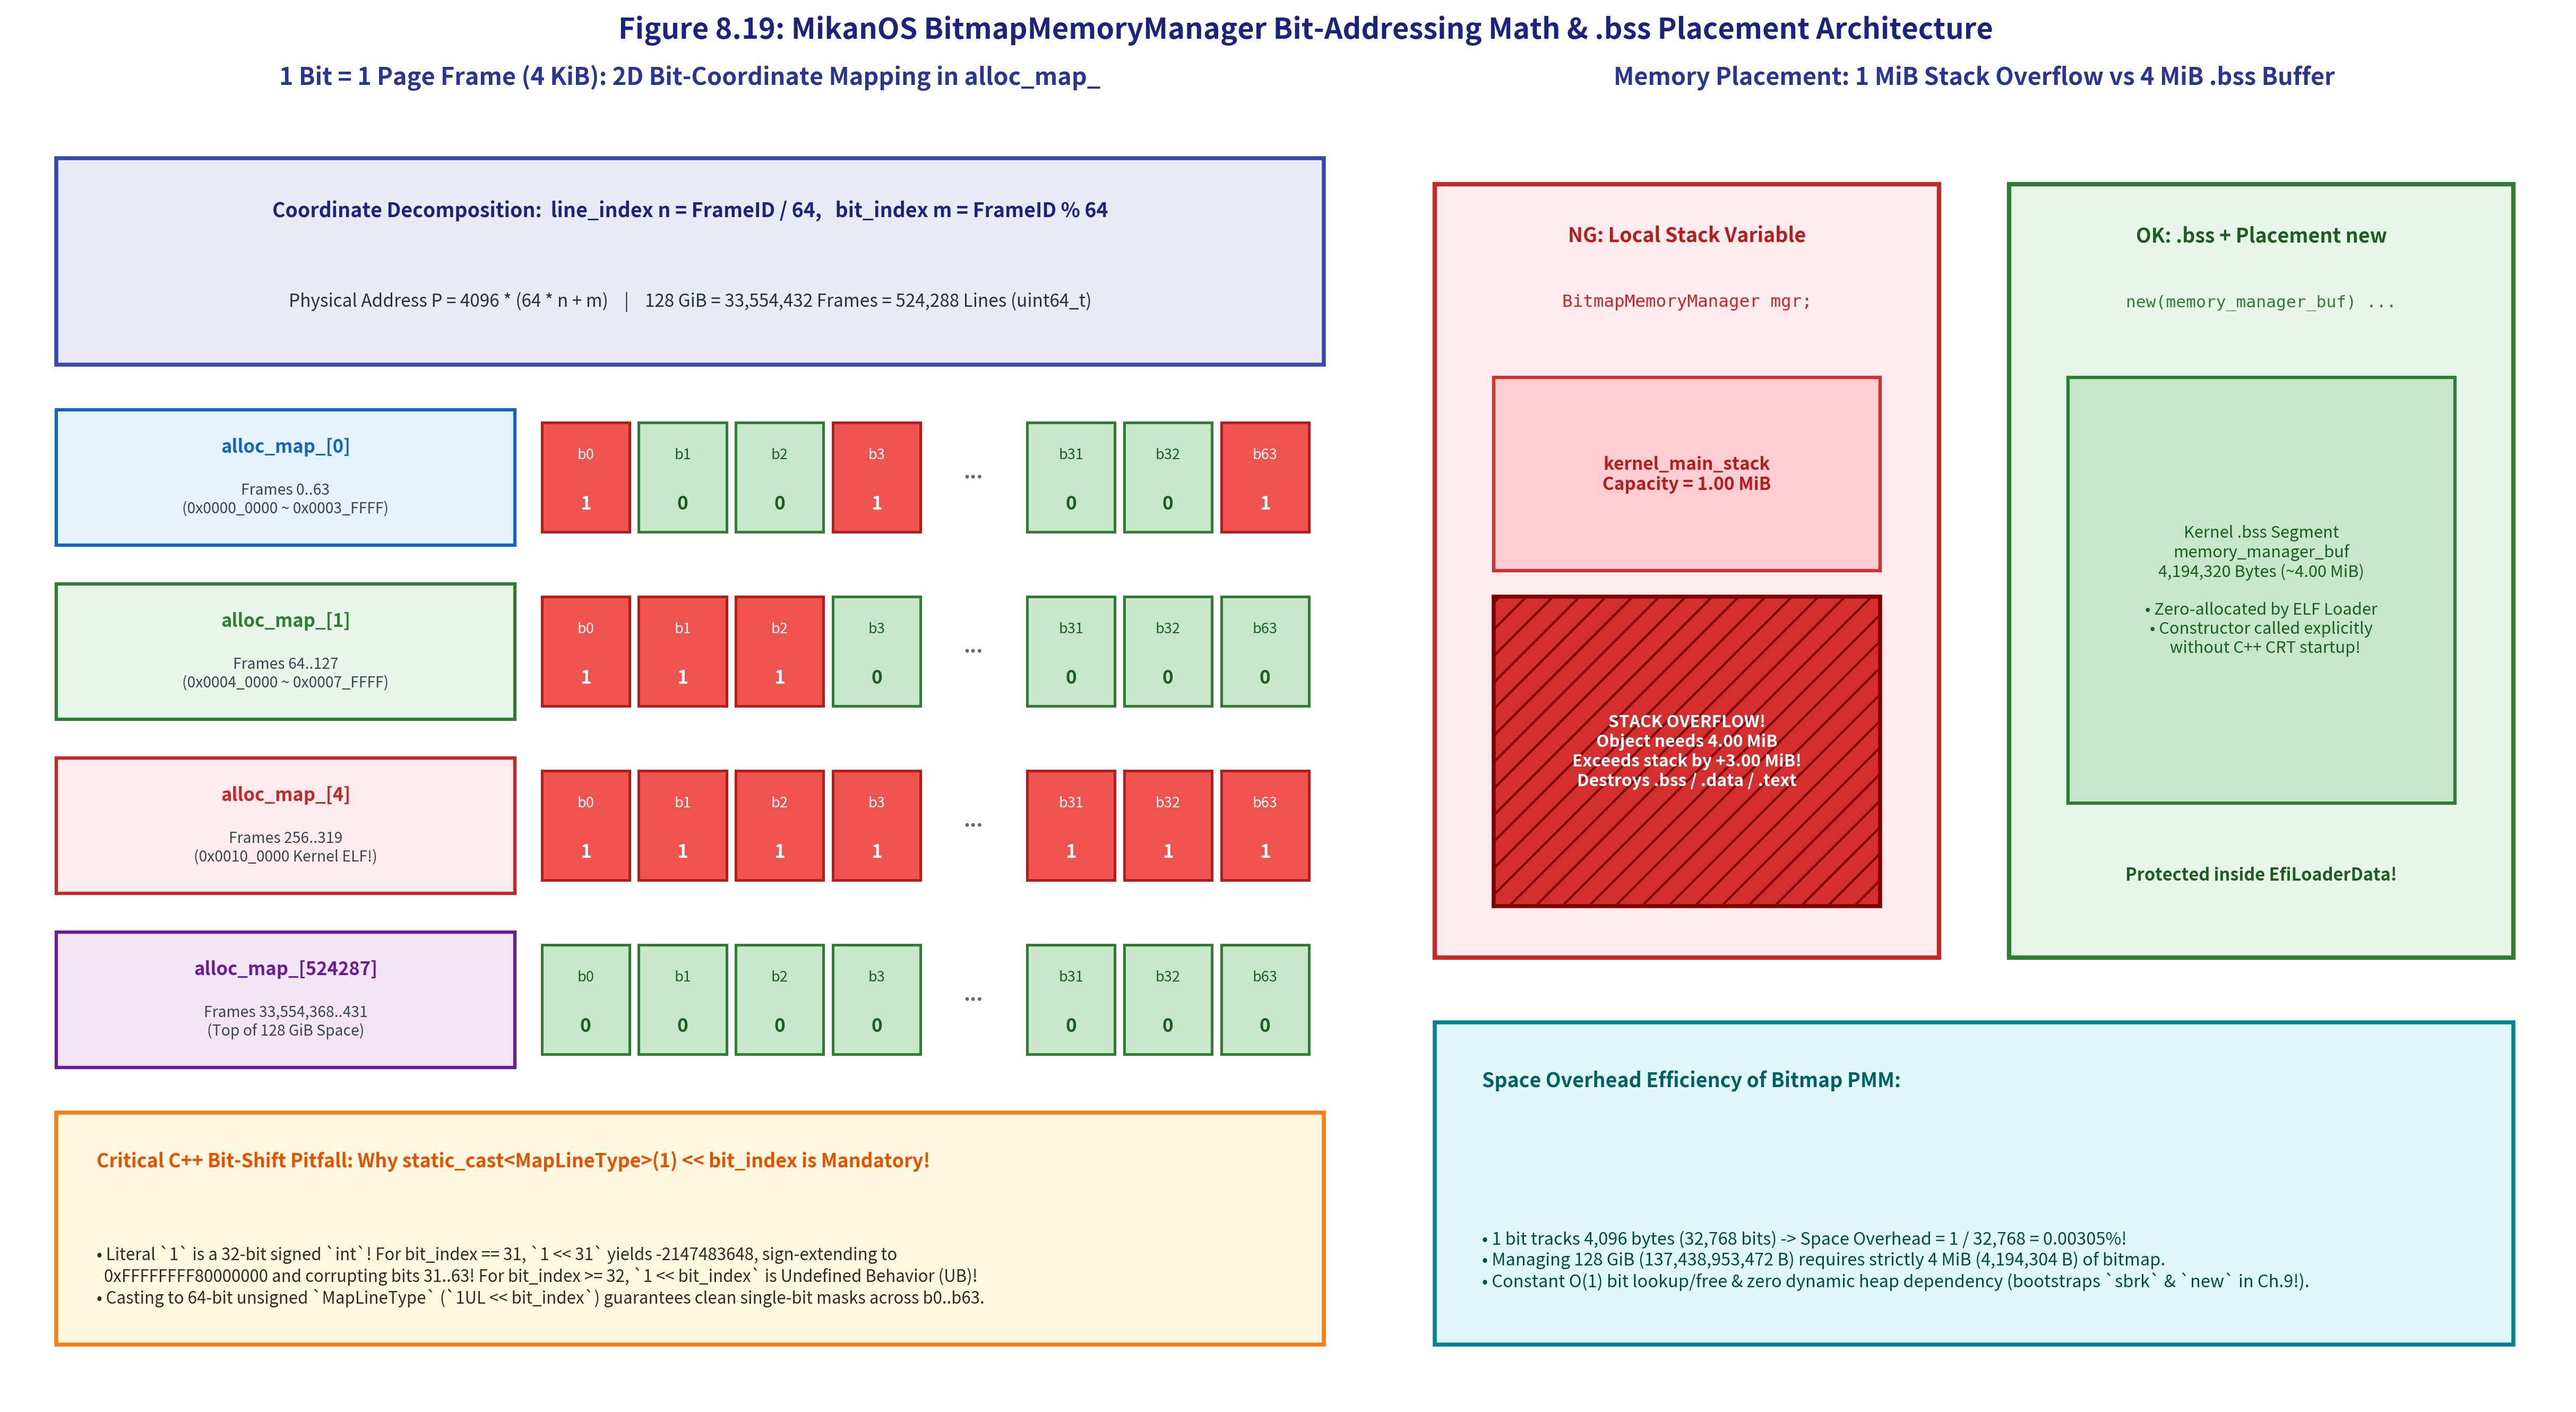

=== 1. MikanOS 128GiB BitmapMemoryManager 構造体メトリクス検証 ===
・最大管理物理メモリ容量     : 128 GiB (137,438,953,472 Bytes)
・総ページフレーム数 (4KiB)  : 33,554,432 フレーム
・MapLineType ビット幅       : 64 bits (uint64_t)
・alloc_map_ 配列要素数      : 524,288 行 (4.00 MiB = 4,194,304 Bytes)
・sizeof(BitmapMemoryManager): 4,194,320 Bytes
・8.4節 カーネルスタック容量 : 1,048,576 Bytes (1.00 MiB)
・スタック配置時の超過サイズ : +3,145,744 Bytes (スタックオーバーフロー確定！)
・ビットマップ空間オーバーヘッド: 0.00305% (わずか 1 / 32,768)

=== 2. 2次元ビット座標変換 (FrameID <-> line_index, bit_index) ===
  FrameID{         0} -> alloc_map_[      0] bit  0 | 物理先頭アドレス: 0x0000000000
  FrameID{         1} -> alloc_map_[      0] bit  1 | 物理先頭アドレス: 0x0000001000
  FrameID{        31} -> alloc_map_[      0] bit 31 | 物理先頭アドレス: 0x000001f000
  FrameID{        63} -> alloc_map_[      0] bit 63 | 物理先頭アドレス: 0x000003f000
  FrameID{        64} -> alloc_map_[      1] bit  0 | 物理先頭アドレス: 0x0000040000
  FrameID{       256} -> alloc_map_[      4] bit  0 | 物理先頭アドレス: 0x0000100000
  FrameID{33,554,431} -> alloc_map_[52

In [2]:
# 図8.19 の生成・表示と BitmapMemoryManager のメモリ空間効率・64ビットシフト検証
from IPython.display import Image, display
from common import (
    FrameIDSim,
    MikanBitmapMemoryManagerSim,
    plot_fig8_19_bitmap_memory_manager_architecture,
)

fig19_path = plot_fig8_19_bitmap_memory_manager_architecture()
display(Image(filename=fig19_path))

metrics = MikanBitmapMemoryManagerSim.full_spec_metrics()
print("=== 1. MikanOS 128GiB BitmapMemoryManager 構造体メトリクス検証 ===")
print(f"・最大管理物理メモリ容量     : {metrics['max_physical_gib']} GiB ({MikanBitmapMemoryManagerSim.MAX_PHYSICAL_MEMORY_BYTES:,} Bytes)")
print(f"・総ページフレーム数 (4KiB)  : {metrics['total_frames']:,} フレーム")
print(f"・MapLineType ビット幅       : {metrics['bits_per_map_line']} bits (uint64_t)")
print(f"・alloc_map_ 配列要素数      : {metrics['map_line_count']:,} 行 ({metrics['alloc_map_mib']:.2f} MiB = {metrics['alloc_map_bytes']:,} Bytes)")
print(f"・sizeof(BitmapMemoryManager): {metrics['sizeof_bitmap_memory_manager']:,} Bytes")
print(f"・8.4節 カーネルスタック容量 : {metrics['kernel_stack_bytes']:,} Bytes (1.00 MiB)")
print(f"・スタック配置時の超過サイズ : +{metrics['stack_overflow_excess_bytes']:,} Bytes (スタックオーバーフロー確定！)")
print(f"・ビットマップ空間オーバーヘッド: {metrics['overhead_percentage']:.5f}% (わずか 1 / 32,768)")

print("\n=== 2. 2次元ビット座標変換 (FrameID <-> line_index, bit_index) ===")
for sample_fid in [0, 1, 31, 63, 64, 256, 33_554_431]:
    line_idx, bit_idx = MikanBitmapMemoryManagerSim.line_and_bit(sample_fid)
    phys_addr = FrameIDSim(sample_fid).frame_address
    print(f"  FrameID{{{sample_fid:10,d}}} -> alloc_map_[{line_idx:7,d}] bit {bit_idx:2d} | 物理先頭アドレス: 0x{phys_addr:010x}")

print("\n=== 3. 32ビット符号付き `1 << bit_index` バグ vs 安全な 64ビットキャスト比較 ===")
for b in [0, 30, 31, 32, 63]:
    sim_res = MikanBitmapMemoryManagerSim.simulate_signed_32bit_shift_bug(b)
    print(
        f"  bit_index={b:2d} | 正解(64bit): 0x{sim_res['safe_mask_64']:016x} "
        f"| バグ(32bit int): 0x{sim_res['buggy_mask_64']:016x} [{sim_res['status']}]"
    )


---

## 3. `memory_manager.cpp` の実装：First-Fit 連続探索と $\mathcal{O}(N)$ ジャンプ最適化

次に、物理フレームの動的確保と解放を担う `kernel/memory_manager.cpp` のアルゴリズムを精読します。

```cpp
WithError<FrameID> BitmapMemoryManager::Allocate(size_t num_frames) {
  size_t start_frame_id = range_begin_.ID();
  while (true) {
    size_t i = 0;
    for (; i < num_frames; ++i) {
      if (start_frame_id + i >= range_end_.ID()) {
        return {kNullFrame, MAKE_ERROR(Error::kNoEnoughMemory)};
      }
      if (GetBit(FrameID{start_frame_id + i})) {
        // "start_frame_id + i" にあるフレームは割り当て済み
        break;
      }
    }
    if (i == num_frames) {
      // num_frames 分の空きが見つかった
      MarkAllocated(FrameID{start_frame_id}, num_frames);
      return {
        FrameID{start_frame_id},
        MAKE_ERROR(Error::kSuccess),
      };
    }
    // 次のフレームから再検索
    start_frame_id += i + 1;
  }
}

Error BitmapMemoryManager::Free(FrameID start_frame, size_t num_frames) {
  for (size_t i = 0; i < num_frames; ++i) {
    SetBit(FrameID{start_frame.ID() + i}, false);
  }
  return MAKE_ERROR(Error::kSuccess);
}
```

### 3.1 First-Fit アルゴリズムと `start_frame_id += i + 1` の数学的証明

`Allocate(num_frames)` は、管理範囲の先頭 `range_begin_` から順に走査し、**最初に発見した $k = \text{num\_frames}$ 個連続する空きフレーム（ビット `0`）を即座に採用する First-Fit（最初適合）法** を実装しています。

ここで最も美しい最適化が、内側ループが `break` した直後の **1行：`start_frame_id += i + 1;`** です。
素朴な二重ループであれば `start_frame_id += 1;` と 1 つ隣へずらして再探索したくなるところですが、なぜ一気に `i + 1` 個先へジャンプして一切の見落としが起きないのでしょうか？

> **【定理：`start_frame_id += i + 1` スキップの正当性と計算量 $\mathcal{O}(N)$ の証明】**
>
> いま開始候補 $s = \text{start\_frame\_id}$ から長さ $k$ の連続空き領域を探しているとき、オフセット $0, 1, \dots, i-1$（ただし $0 \le i < k$）まではすべて空き（`GetBit == false`）であり、オフセット $i$ すなわちフレーム **$s + i$ が使用中（`GetBit == true`）** で衝突したとする。
>
> このとき、飛ばされる途中の任意の開始候補 $s' \in \{s + 1, s + 2, \dots, s + i\}$ を考える。
> $s'$ から始まる長さ $k$ の要求区間 $[s',\; s' + k - 1]$ の下端と上端を評価すると：
> 1. 下端：$s' \le s + i$
> 2. 上端：$s' \ge s + 1$ および $i < k \iff i \le k - 1$ より、
>    $$s' + k - 1 \ge (s + 1) + k - 1 = s + k > s + i$$
>
> したがって、すべての $s' \in [s + 1, s + i]$ について
> $$s' \le s + i \le s' + k - 1$$
> が恒等的に成り立つ！すなわち、**$[s+1, s+i]$ のどこから開始しても、長さ $k$ の窓は必ず使用中フレーム $s + i$ を跨いでしまい 100% 失敗する**。
>
> よって次の有効な開始候補は厳密に $s_{\text{next}} = s + i + 1$ であり、この更新規則のもとでは管理範囲 $[\text{range\_begin\_}, \text{range\_end\_})$ 内の全 $N$ フレームについて **`GetBit` は各フレーム高々 1 回しか呼び出されない**。ゆえに最悪時間計算量は要求サイズ $k$ に依存しない厳密な線形時間 **$\mathcal{O}(N)$** となる（素朴な `+1` 更新の最悪計算量 $\mathcal{O}(N \cdot k)$ を劇的に改善！）。 $\blacksquare$

また、ビット読み書きを `GetBit` / `SetBit` に抽象化した恩恵として、たとえば `FrameID{62}` から 4 フレーム（`62, 63, 64, 65`）を確保する場合のように **`alloc_map_[0]` と `alloc_map_[1]` の 64ビット境界を跨ぐ連続割り当て** も、呼び出し側で一切の境界分岐を書くことなく完全に透過的に動作します（公式単体テスト `AllocateMultipleLine` で検証される重要性質です）。

---

### 3.2 `Free()` と外部断片化（External Fragmentation）・自動合体（Auto-Coalescing）

`Free(start_frame, num_frames)` に解放フレーム数 `num_frames` を呼び出し側が渡す設計になっている点にも注目してください。
C 言語の `free(ptr)` はサイズ引数を持ちませんが、それは `malloc` が割り当てブロックの直前数バイトに「ヘッダ（サイズ情報）」をこっそり埋め込んでいるからです。もし 4KiB アライメントが命であるページフレームの内部にヘッダを書き込んでしまうと、ページテーブル（4KiB まるごと使う）として利用できなくなってしまいます。そのため物理フレーム管理層ではヘッダを持たず、サイズ管理は第9章で構築する上位のバイトアロケータ（`malloc` / `new`）や各ドライバが保持する美しい階層分担になっています。

また、複数フレームの確保と解放を繰り返すと、空きフレームの合計数は十分にあるにもかかわらず、使用中フレームが邪魔をして連続した大きな領域が取れなくなる **外部断片化（External Fragmentation）** が発生します：

$$\text{External Fragmentation Ratio} = 1 - \frac{\text{最大連続空きフレーム数 (Largest Contiguous Free Run)}}{\text{合計空きフレーム数 (Total Free Frames)}}$$

連結リスト方式のアロケータでは、解放時に前後の空きブロックを探してポインタを繋ぎ直す複雑な「コアレッシング（Coalescing：隣接ブロック結合）処理」が必要ですが、**ビットマップ方式では該当ビットを `0` に戻すだけで、隣の `0` ビット列と自動的にひとつの連続空き領域として合体（Auto-Coalescing）する** という実装上の大きな強みがあります！


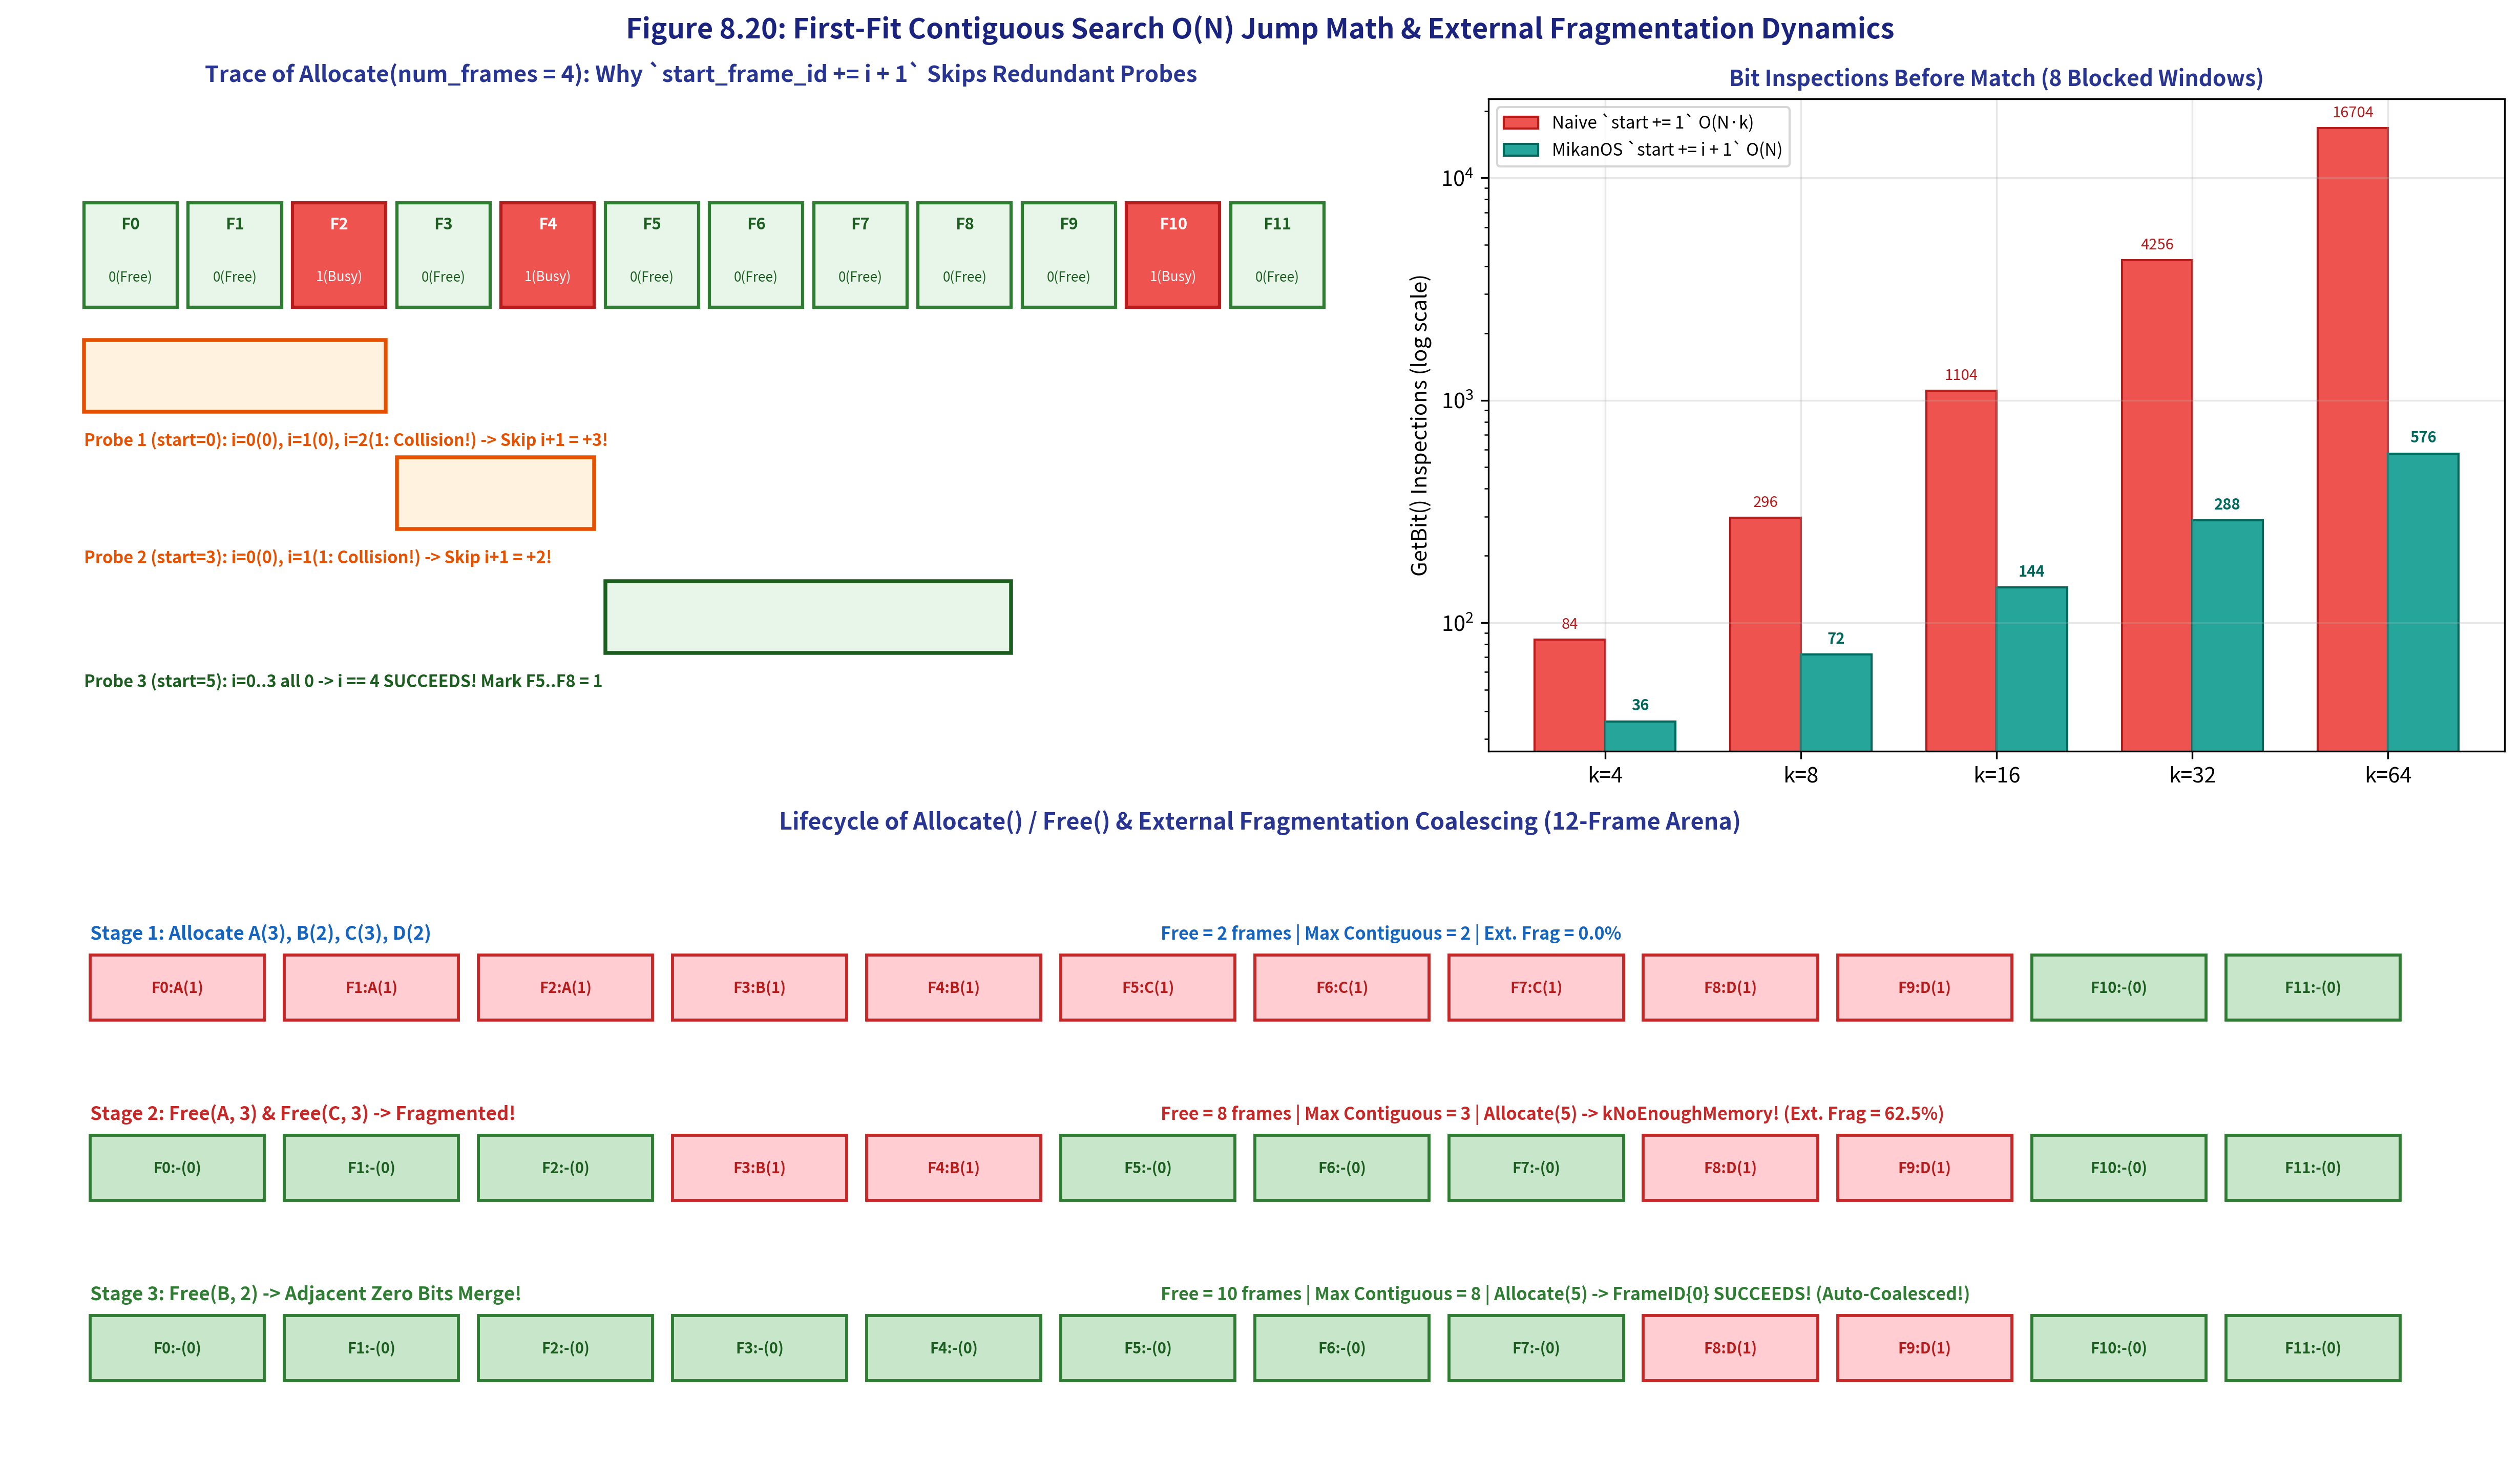

=== 1. Allocate(num_frames=4) の探索ウィンドウ遷移トレース ===
  Probe 1: start=0 -> フレーム 2 が使用中(1)のため衝突！ i+1 = +3 ジャンプして次は start=3 へ
  Probe 2: start=3 -> フレーム 4 が使用中(1)のため衝突！ i+1 = +2 ジャンプして次は start=5 へ
  Probe 3: start=5 -> 4 個連続空き発見！ FrameIDSim(id=5, phys=0x00005000) を確保成功！
  [GetBit 検査回数比較] MikanOS O(N) ジャンプ法: 9 回 vs 素朴な +1 法: 13 回

=== 2. 外部断片化の発生と Free() 自動合体シミュレーション (12フレーム空間) ===
  [断片化状態] 合計空き=8 フレーム, 最大連続空き=3 フレーム, 外部断片化率=62.5% -> Allocate(5) 結果: (FrameIDSim(kNullFrame), error=kNoEnoughMemory)
  [B解放・合体後] 合計空き=10 フレーム, 最大連続空き=8 フレーム, 外部断片化率=20.0% -> Allocate(5) 結果: (FrameIDSim(id=0, phys=0x00000000), error=None)


In [3]:
# 図8.20 の生成・表示と First-Fit O(N) ジャンプ追跡・外部断片化実験
from IPython.display import Image, display
from common import (
    FrameIDSim,
    MikanBitmapMemoryManagerSim,
    plot_fig8_20_first_fit_allocation_and_skip_math,
)

fig20_path = plot_fig8_20_first_fit_allocation_and_skip_math()
display(Image(filename=fig20_path))

# 1. O(N) スキップ探索のステップ追跡実験
sim_trace = MikanBitmapMemoryManagerSim(frame_count=64)
sim_trace.set_memory_range(FrameIDSim(0), FrameIDSim(16))
# フレーム 2, 4, 10 を使用中(1)に設定し、4連続フレームを要求
for busy_id in [2, 4, 10]:
    sim_trace.mark_allocated(FrameIDSim(busy_id), 1)

trace_result = sim_trace.allocate_with_trace(4)
print("=== 1. Allocate(num_frames=4) の探索ウィンドウ遷移トレース ===")
for step_no, p in enumerate(trace_result["probes"], 1):
    if p["outcome"] == "CollisionJump":
        print(
            f"  Probe {step_no}: start={p['start']} -> フレーム {p['collision_frame']} が使用中(1)のため衝突！ "
            f"i+1 = +{p['skip_distance']} ジャンプして次は start={p['next_start']} へ"
        )
    else:
        print(f"  Probe {step_no}: start={p['start']} -> {p['checked_len']} 個連続空き発見！ {trace_result['frame']} を確保成功！")
print(f"  [GetBit 検査回数比較] MikanOS O(N) ジャンプ法: {trace_result['jump_checks']} 回 vs 素朴な +1 法: {trace_result['naive_checks']} 回")

# 2. 外部断片化 (External Fragmentation) と Free() による自動合体 (Auto-Coalescing) 実験
print("\n=== 2. 外部断片化の発生と Free() 自動合体シミュレーション (12フレーム空間) ===")
arena = MikanBitmapMemoryManagerSim(frame_count=64)
arena.set_memory_range(FrameIDSim(0), FrameIDSim(12))
f_a, _ = arena.allocate(3)  # Frames 0..2
f_b, _ = arena.allocate(2)  # Frames 3..4
f_c, _ = arena.allocate(3)  # Frames 5..7
f_d, _ = arena.allocate(2)  # Frames 8..9

arena.free(f_a, 3)
arena.free(f_c, 3)
frag_before = arena.fragmentation_metrics()
failed_frame, err_code = arena.allocate(5)
print(
    f"  [断片化状態] 合計空き={frag_before['free_frames']} フレーム, 最大連続空き={frag_before['largest_contiguous_free']} フレーム, "
    f"外部断片化率={frag_before['external_fragmentation_ratio']*100:.1f}% -> Allocate(5) 結果: ({failed_frame}, error={err_code})"
)

# 真ん中の B (Frames 3..4) を解放すると、[0..2] + [3..4] + [5..7] = [0..7] の 8連続空きフレームに自動合体！
arena.free(f_b, 2)
frag_after = arena.fragmentation_metrics()
ok_frame, err_code2 = arena.allocate(5)
print(
    f"  [B解放・合体後] 合計空き={frag_after['free_frames']} フレーム, 最大連続空き={frag_after['largest_contiguous_free']} フレーム, "
    f"外部断片化率={frag_after['external_fragmentation_ratio']*100:.1f}% -> Allocate(5) 結果: ({ok_frame}, error={err_code2})"
)


---

## 4. `kernel/main.cpp` における UEFI `MemoryMap` 走査初期化とホスト単体テスト

完成した `BitmapMemoryManager` に実際の PC / QEMU の物理メモリ構成を教え込むのが、`kernel/main.cpp`（`KernelMainNewStack` 内）の初期化ループです。一見するとわずか 25 行ほどの短いコードですが、ここには OS 開発の極めて精巧な **3 つの安全不変条件（Invariants）** が凝縮されています！

```cpp
alignas(BitmapMemoryManager) char memory_manager_buf[sizeof(BitmapMemoryManager)];
BitmapMemoryManager* memory_manager;

// KernelMainNewStack 内:
const std::array available_memory_types{
  MemoryType::kEfiBootServicesCode,
  MemoryType::kEfiBootServicesData,
  MemoryType::kEfiConventionalMemory,
};

memory_manager = new(memory_manager_buf) BitmapMemoryManager;

const auto memory_map_base = reinterpret_cast<uintptr_t>(memory_map.buffer);
uintptr_t available_end = 0;
for (uintptr_t iter = memory_map_base;
     iter < memory_map_base + memory_map.map_size;
     iter += memory_map.descriptor_size) {
  auto desc = reinterpret_cast<const MemoryDescriptor*>(iter);
  if (available_end < desc->physical_start) {
    memory_manager->MarkAllocated(
        FrameID{available_end / kBytesPerFrame},
        (desc->physical_start - available_end) / kBytesPerFrame);
  }

  const auto physical_end =
      desc->physical_start + desc->number_of_pages * kUEFIPageSize;
  if (IsAvailable(static_cast<MemoryType>(desc->type))) {
    available_end = physical_end;
  } else {
    memory_manager->MarkAllocated(
        FrameID{desc->physical_start / kBytesPerFrame},
        desc->number_of_pages * kUEFIPageSize / kBytesPerFrame);
  }
}
memory_manager->SetMemoryRange(FrameID{1}, FrameID{available_end / kBytesPerFrame});
```

### 4.1 初期化ループが守る「3 大安全不変条件」の徹底解剖

1. **不変条件①：未記載メモリホール（Memory Hole）の完全封印**
   `BitmapMemoryManager` のコンストラクタ直後、`alloc_map_` はゼロ初期化されているため、**全フレームが一旦 `0`（空き）** としてスタートします。
   ところが UEFI の `MemoryMap` は物理アドレス順に並んでいても、記述子と記述子の間に**そもそもマップに載っていない空白地帯（例：`0x000A0000〜0x000FFFFF` のレガシー VGA VRAM / BIOS ROM 領域や PCI バス予約穴）**が存在します。もし記述子だけを処理すると、これらの危険な穴が初期値 `0`（空き）のまま放置されてしまいます！
   そこで `if (available_end < desc->physical_start)` によって前の利用可能領域末尾から現在の記述子先頭までのギャップを一括で `MarkAllocated`（`1`）し、未記載ホールを確実にロックします。

2. **不変条件②：カーネル自身（`.text` / `.data` / `.bss`）の自動保護**
   「カーネル自身の機械語コード、1MiB スタック、64GiB ページテーブル、そして 4MiB の `memory_manager_buf` 自体はなぜ上書きされないのか？」という疑問の答えもこのループにあります。
   第4章で作成したブートローダは、カーネル ELF をロードする先の物理ページを UEFI の `AllocatePages` で **`kEfiLoaderData`** タイプとして確保しました。`IsAvailable()` が `true` を返すのは以下の 3 種類だけです：
   - `kEfiBootServicesCode` (3): ブートサービス終了により回収・再利用可能になった元ファームウェアコード領域
   - `kEfiBootServicesData` (4): 同、回収・再利用可能になった元ファームウェアデータ領域（旧ページテーブル等）
   - `kEfiConventionalMemory` (7): 最初から誰にも使われていない純粋な空き RAM

   したがって **`kEfiLoaderData` は `IsAvailable == false` と判定され、自動的に `MarkAllocated`（使用中 `1`）として永久保護される** のです！（同様に ACPI テーブルや `kEfiRuntimeServicesCode/Data` も保護されます）。

3. **不変条件③：`available_end` の冪等スイープと 4GiB MMIO 除外 ＋ `FrameID{1}` の `nullptr` ガード**
   さらに鋭い観察ポイントは、**`available_end` が `IsAvailable == true` のときにしか更新されない** ことです！
   - 非空き領域（`EfiLoaderData` 等）を処理した時点では `available_end` は前進しません。次の記述子に進んだ際、`available_end < desc->physical_start` が再び真となって非空き領域の上をもう一度 `MarkAllocated` でなぞりますが、ビットへの `1` 書き込み（`|= mask`）は**冪等（Idempotent：何度実行しても結果が同じ）**なので一切無害であり、かつ非空き領域の直後にさらに未記載ホールが連続していても漏れなく両方ロックできます。
   - そして何より、`MemoryMap` の末尾には物理アドレス `0xFEE00000`（約 4GiB 付近の Local APIC / IOAPIC 等）といった **`kEfiMemoryMappedIO` 記述子** が現れます。もし毎回末尾アドレスを更新していたら、`range_end_` が実装 RAM（例：128MiB）を遥かに超えて 4GiB まで膨張してしまいます！`IsAvailable` のときだけ `available_end` を更新する設計により、**`range_end_` は「実際に使える最終物理 RAM の直後」にピタリと収まります**。
   - 最後に `SetMemoryRange(FrameID{1}, ...)` と開始フレームを **`FrameID{0}` ではなく `FrameID{1}`（物理アドレス `0x1000`）** に設定します。恒等マッピング環境では `FrameID{0}.Frame()` はアドレス `0x0` すなわち **C/C++ のヌルポインタ（`nullptr`）そのもの** になってしまうため、フレーム 0 を検索対象から外すことで「正当に確保したポインタが `nullptr` と判定されて誤動作するバグ」を根絶しています。

---

### 4.2 公式ホスト単体テスト（`kernel/test/test_memory_manager.cpp`）の導入

`osbook_day08c` のもうひとつの歴史的マイルストーンは、MikanOS リポジトリに初めて **ホスト OS 上で高速実行できる単体テスト（`CppUTest` フレームワークによる `kernel/test/test_memory_manager.cpp`）** が導入されたことです。
QEMU を毎回起動して目視確認するだけでは、64ビット境界跨ぎやメモリ枯渇時の境界バグを見逃しがちです。ハードウェアレジスタ（CR3 や I/O ポート）に直接触れない純粋なデータ構造・アルゴリズムとして `BitmapMemoryManager` を分離設計したからこそ、以下の公式 7 テストケースをミリ秒単位で自動検証できます：

1. **`Allocate`**: `Allocate(3)` に続けて `Allocate(1)` を呼び、フレーム `0..2` の直後のフレーム `3` が返ること。
2. **`AllocateMultipleLine`**: `Allocate(kBitsPerMapLine + 3)`（67 フレーム）で `alloc_map_[0]` と `alloc_map_[1]` の行境界を跨ぐ連続確保が正しく行われること。
3. **`AllocateNoEnoughMemory`**: 全領域を超える `Allocate(kFrameCount + 1)` が `{kNullFrame, Error::kNoEnoughMemory}` を返すこと。
4. **`Free`**: 確保した領域を `Free` すると、再び同じ先頭フレームから再確保できること。
5. **`FreeDifferentFrames`**: 別フレームを解放しても他の使用中フレームが誤解放されず、適切な空き区間から確保されること。
6. **`MarkAllocated`**: 事前予約区間（例：フレーム `5..9`）を避けて、手前または後ろの連続領域から正しく First-Fit 確保されること。
7. **`SetMemoryRange`**: `[FrameID{10}, FrameID{64})` のように検索窓を絞った際、`FrameID{10}` から割り当てが始まり、`FrameID{64}` を超える要求は確実に `kNoEnoughMemory` になること。


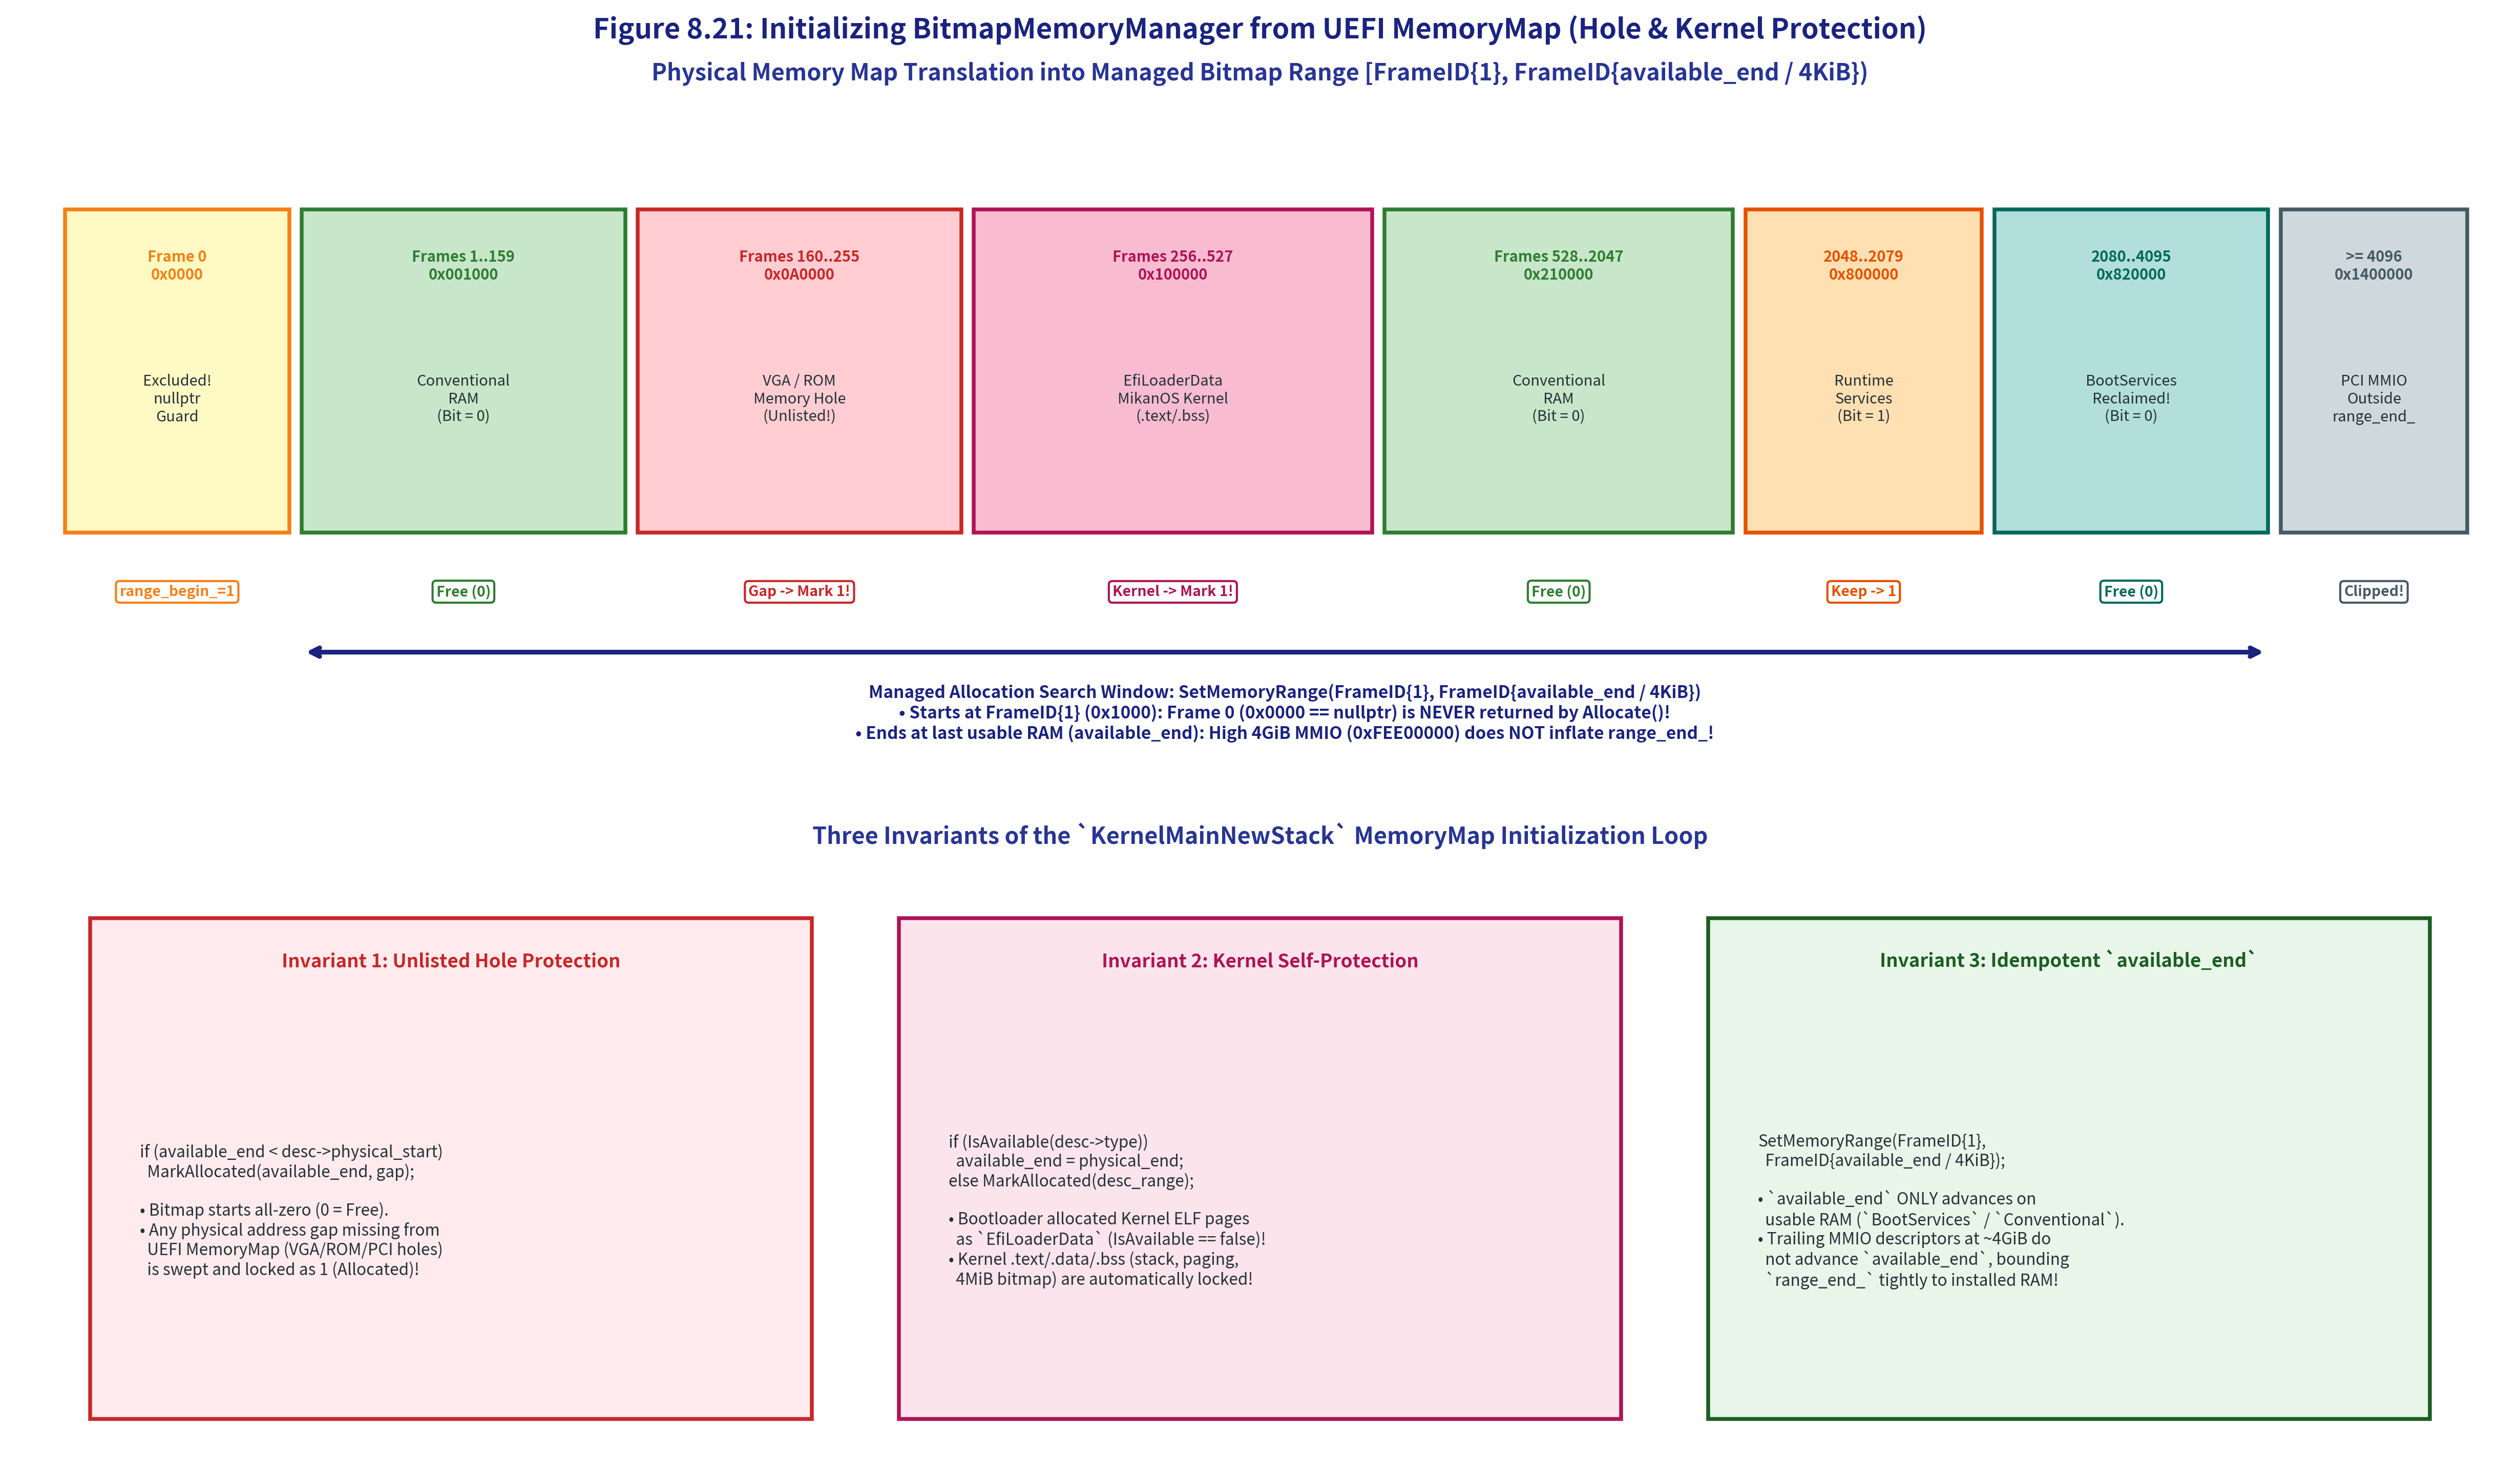

=== UEFI MemoryMap -> BitmapMemoryManager 初期化トレース結果 ===
・最終利用可能物理アドレス (available_end) : 0x01000000 (16 MiB)
・設定された検索範囲 [range_begin, range_end): [FrameID{1}, FrameID{4096})
・検出された未記載メモリホール             : [('0xa0000', '0x100000'), ('0x1000000', '0x1400000')]
・管理範囲内の空きフレーム数 (Bit=0)       : 3,695 フレーム (14.43 MiB)
・管理範囲内の保護済みフレーム数 (Bit=1)   : 400 フレーム (VGA穴 96 + Kernel 272 + Runtime 32 = 400)

=== 初回 Allocate(1) 安全性チェック ===
・返却されたフレーム: FrameIDSim(id=1, phys=0x00001000) (error=None) -> Frame 0 (nullptr=0x0) ではなく 0x1000 が確実に返る！
・VGA ROM ホール先頭 (Frame 160 = 0xA0000) のビット状態 : 保護済み(1)
・カーネル配置先頭   (Frame 256 = 0x100000) のビット状態: 保護済み(1)


In [4]:
# 図8.21 の生成・表示と UEFI MemoryMap 走査初期化シミュレーション
from IPython.display import Image, display
from common import (
    FrameIDSim,
    MikanBitmapMemoryManagerSim,
    plot_fig8_21_uefi_memmap_to_bitmap_initialization,
)

fig21_path = plot_fig8_21_uefi_memmap_to_bitmap_initialization()
display(Image(filename=fig21_path))

# QEMU/OVMF 風のリアルな UEFI MemoryMap 記述子リスト: (MemoryType, physical_start, number_of_pages)
# MemoryType: 3=BootServicesCode, 4=BootServicesData, 7=ConventionalMemory (以上3つが Available),
#             2=EfiLoaderData (Kernel ELF), 6=RuntimeServicesData, 11=MemoryMappedIO
realistic_descriptors = [
    (3, 0x0000_0000, 1),      # Frame 0      : EfiBootServicesCode (Available だが FrameID{1} 開始で除外される！)
    (7, 0x0000_1000, 159),    # Frames 1..159: Conventional RAM (636 KiB)
    # ★ 0x000A_0000 .. 0x0010_0000 (Frames 160..255: 384 KiB) は記述子が存在しない VGA / BIOS ROM メモリホール！
    (2, 0x0010_0000, 272),    # Frames 256..527 : EfiLoaderData (MikanOS カーネル .text/.data/.bss 本体！)
    (7, 0x0021_0000, 1520),   # Frames 528..2047: Conventional RAM
    (6, 0x0080_0000, 32),     # Frames 2048..2079: EfiRuntimeServicesData (UEFI ランタイム領域 -> 保護)
    (4, 0x0082_0000, 2016),   # Frames 2080..4095: EfiBootServicesData (ExitBootServices 後に回収・再利用！)
    # ★ 0x0100_0000 .. 0x0140_0000 (Frames 4096..5119) 未記載ギャップ + 末尾 MMIO 領域
    (11, 0x0140_0000, 16),    # Frames 5120..5135: MemoryMappedIO (available_end を膨張させない！)
]

pmm = MikanBitmapMemoryManagerSim(frame_count=8192)
summary = pmm.initialize_from_uefi_descriptors(realistic_descriptors)

print("=== UEFI MemoryMap -> BitmapMemoryManager 初期化トレース結果 ===")
print(f"・最終利用可能物理アドレス (available_end) : 0x{summary['available_end']:08x} ({summary['available_end'] // (1024*1024)} MiB)")
print(f"・設定された検索範囲 [range_begin, range_end): [FrameID{{{summary['range_begin']}}}, FrameID{{{summary['range_end']}}})")
print(f"・検出された未記載メモリホール             : {[(hex(s), hex(e)) for s, e in summary['unlisted_holes']]}")
print(f"・管理範囲内の空きフレーム数 (Bit=0)       : {summary['free_frames']:,} フレーム ({summary['free_frames']*4/1024:.2f} MiB)")
print(f"・管理範囲内の保護済みフレーム数 (Bit=1)   : {summary['allocated_frames']:,} フレーム (VGA穴 96 + Kernel 272 + Runtime 32 = 400)")

first_alloc, err = pmm.allocate(1)
print(f"\n=== 初回 Allocate(1) 安全性チェック ===")
print(f"・返却されたフレーム: {first_alloc} (error={err}) -> Frame 0 (nullptr=0x0) ではなく 0x1000 が確実に返る！")
print(f"・VGA ROM ホール先頭 (Frame 160 = 0xA0000) のビット状態 : {'保護済み(1)' if pmm.get_bit(FrameIDSim(160)) else '危険(0)'}")
print(f"・カーネル配置先頭   (Frame 256 = 0x100000) のビット状態: {'保護済み(1)' if pmm.get_bit(FrameIDSim(256)) else '危険(0)'}")


In [5]:
# C++20 BitmapMemoryManager シミュレータのコンパイルと公式準拠単体テスト実行
import os
import subprocess

cpp_source = "src/ch08/bitmap_memory_manager_sim.cpp"
bin_dir = "build/bin"
bin_path = os.path.join(bin_dir, "ch08_bitmap_memory_manager_sim")

os.makedirs(bin_dir, exist_ok=True)

# g++ で C++20 最適化コンパイル (-Wall -Wextra 警告ゼロ検証)
compile_cmd = ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", cpp_source, "-o", bin_path]
print("Compiling C++20 simulator:", " ".join(compile_cmd))
subprocess.run(compile_cmd, check=True)

# 1. デモ実行（128GiB Placement new 実証・O(N) スキップ計測・UEFI MemoryMap 初期化）
print("\n=== C++20 Simulator Demo Output ===")
res_demo = subprocess.run([bin_path], capture_output=True, text=True, check=True)
print(res_demo.stdout)

# 2. 単体テスト実行 (--test: osbook_day08c 公式 CppUTest 全7ケース + 境界検証)
print("=== Running C++20 Verification Unit Tests (--test) ===")
res_test = subprocess.run([bin_path, "--test"], capture_output=True, text=True, check=True)
print(res_test.stdout)


Compiling C++20 simulator: g++ -std=c++20 -O2 -Wall -Wextra src/ch08/bitmap_memory_manager_sim.cpp -o build/bin/ch08_bitmap_memory_manager_sim



=== C++20 Simulator Demo Output ===
  MikanOS Chapter 8.7: BitmapMemoryManager Simulator (osbook_day08c)
1. Structural & Memory Footprint Specifications:
   kBytesPerFrame          : 4096 B (4 KiB)
   kMaxPhysicalMemoryBytes : 128 GiB
   kFrameCount             : 33554432 frames
   kBitsPerMapLine         : 64 bits (uint64_t)
   alloc_map_ lines        : 524288 lines
   sizeof(BitmapMemoryMgr) : 4194320 bytes (~4.00 MiB)

2. UEFI MemoryMap Initialization Summary:
   Managed Range           : [Frame 1, Frame 4096) -> [0x1000, 0x1000000)
   Memory Holes Protected  : 2 holes (1120 frames, 4 idempotent sweeps)
   Free Frames Available   : 3695 frames (14780 KiB)

3. Sample Contiguous Frame Allocations:
   Allocate(4 frames)      -> FrameID{1} (Phys: 0x00001000)
   Allocate(200 frames)    -> FrameID{528} (Phys: 0x00210000) [Safely skipped VGA Hole & Kernel ELF!]

=== Running C++20 Verification Unit Tests (--test) ===
All C++20 BitmapMemoryManager Verification Unit Tests Passed Successfully

---

## 5. 実装上の落とし穴とデバッグ指針 (Common Pitfalls & Traps)

物理メモリマネージャの実装では、たった 1 ビットの計算ミスが数時間後・数千回後のメモリ確保で突発的なカーネルパニックを引き起こします。代表的な 4 つの落とし穴を整理しておきましょう。

### 落とし穴 1: `BitmapMemoryManager` をローカル変数として宣言してしまう
- **症状**: `KernelMainNewStack` に入った直後、画面描画すら始まる前に QEMU が無限再起動（Triple Fault）する。
- **原因**: `sizeof(BitmapMemoryManager)` は **4 MiB（4,194,320 Bytes）** あります。1 MiB の `kernel_main_stack` 上にローカル変数として確保すると、関数プロローグの `sub rsp, 4194320` 相当のスタック伸長とゼロ初期化によって `.bss` 上のページテーブルや GDT を即座に踏み潰します。
- **対策**: 必ず `.bss` セクションに `alignas(BitmapMemoryManager) char memory_manager_buf[sizeof(BitmapMemoryManager)];` を静的配置し、配置 `new` で初期化すること。

### 落とし穴 2: `1 << bit_index` と 32ビットリテラルでシフトしてしまう
- **症状**: 30 フレーム目までは正常に動くのに、31 フレーム目〜63 フレーム目を確保・解放した途端に他のフレームが勝手に使用中になったり解放されたりする。
- **原因**: リテラル `1` は 32ビット符号付き `int` であるため、`1 << 31` の符号拡張（`0xFFFFFFFF80000000`）および `bit_index >= 32` での未定義動作が発生します。
- **対策**: ビットマスク生成時は必ず **`static_cast<MapLineType>(1) << bit_index`**（または `1UL << bit_index`）と 64ビット符号なし型へキャストしてからシフトすること。

### 落とし穴 3: `SetMemoryRange` の開始フレームを `FrameID{0}` にしてしまう
- **症状**: 最初の `Allocate()` で確保したメモリをポインタに変換して `if (ptr == nullptr)` でエラーチェックすると、メモリが十分あるのにエラー扱いになる（あるいは C++ の未定義動作を誘発する）。
- **原因**: 恒等マッピング下では `FrameID{0}.Frame()` は `0x0`（`nullptr`）に一致します。また PC アーキテクチャの物理アドレス `0x0000` 付近にはリアルモード IVT / BIOS データ領域の名残があることも多く、触らないのが鉄則です。
- **対策**: 管理開始フレームは必ず **`FrameID{1}`（物理アドレス `0x1000`）** 以上に設定すること。

### 落とし穴 4: `available_end` を非空き記述子（MMIO 等）でも無条件更新してしまう
- **症状**: 搭載 RAM（例：128MiB）を使い切った後、`kNoEnoughMemory` にならずに実在しない物理アドレス（例：`0x20000000`）が割り当てられてしまい、書き込み時にバスエラーや異常動作を起こす。
- **原因**: `MemoryMap` 末尾の 4GiB 付近にある `kEfiMemoryMappedIO` 記述子で `available_end` を更新してしまうと、RAM 上限から MMIO 先頭までの巨大な空白地帯が `range_end_` の内側に入ってしまいます。
- **対策**: `available_end = physical_end;` の更新は必ず **`if (IsAvailable(...))` の分岐内のみ** で行うこと。


---

## 6. まとめと次節への展望

### 本節の達成事項と定量サマリ
1. **128GiB 対応 `BitmapMemoryManager` の確立**:
   - 4KiB ページフレームにつき 1 ビットを割り当てることで、空間オーバーヘッド **$\frac{1}{32,768} \approx 0.00305\%$** を達成。最大 **128 GiB（$33,554,432$ フレーム）** の物理空間をわずか **4.00 MiB（$524,288 \times 64\text{-bit}$ 行）** の固定配列で管理可能にしました。
2. **フリースタンディング C++ 制約の克服**:
   - 1MiB カーネルスタックのオーバーフローと CRT 不在という二重の制約を、`.bss` 領域の `memory_manager_buf` と **配置 `new`（Placement `new`）** の組み合わせで完全に解決しました。
3. **First-Fit $\mathcal{O}(N)$ スキップ探索と自動コアレッシング**:
   - 衝突フレームの手前を一括スキップする `start_frame_id += i + 1` により、任意の連続フレーム数 $k$ に対して `GetBit` 検査回数を最悪 $\mathcal{O}(N)$ に抑え、`Free()` 時のビットクリアのみで隣接空き領域が自動合体する仕組みを実証しました。
4. **UEFI `MemoryMap` からの安全な台帳構築とホスト単体テスト**:
   - 未記載の VGA/BIOS メモリホール保護、`EfiLoaderData` によるカーネル自身の保護、`FrameID{1}` による `nullptr` 回避、および 4GiB MMIO の除外をすべて満たす初期化ループを完成させ、`osbook_day08c` 公式 `CppUTest` 全 7 ケースの完全パスを確認しました。

### 次節（第8章 理解度テスト & 演習 / 第9章 重ね合わせ処理）への展望
これで第8章「メモリ管理」のすべての理論と実装（UEFI メモリマップ解析 $\rightarrow$ カーネルスタック移転 $\rightarrow$ GDT 再構築 $\rightarrow$ 64GiB 4階層恒等ページング $\rightarrow$ 128GiB `BitmapMemoryManager`）が揃いました！
- 次の **`8_Exercises.ipynb`（第8章 理解度テスト & 演習）** では、第8章全体の知識を横断する総合演習問題と実践課題に取り組みます。
- そして続く **第9章「重ね合わせ処理」** では、本節で作った `BitmapMemoryManager::Allocate` をバックエンドとして Newlib の **`sbrk()` システムコール** を実装し、ついにカーネル内で **`new` / `delete` や `std::vector` といったバイト単位の動的メモリ確保** を解禁して、マウスカーソルと複数ウィンドウの美しい重ね合わせ描画（`LayerManager`）へと飛躍します！
